In [41]:
import os, sys
sys.path.insert(0, os.getcwd())   # make the hw3 folder win over src/

import numpy as np
import matplotlib.pyplot as plt
from pricer import *

import model
print(model.__file__)             # should end in hw3/model.py

/Users/marleenbuitenhuis/Projects/QuantCourseBP/homeworks/57364de/hw3/model.py


In [42]:
def digital_call_value(spot, strike, expiry, underlying):
    model = MarketModel(underlying)
    model.spot = spot
    contract = EuropeanDigitalContract(underlying, PutCallFwd.CALL, LongShort.LONG, strike, expiry)
    pricer = EuropeanDigitalAnalyticPricer(contract, model, Params())
    return pricer.calc_fair_value()


digital_call_value(spot=100, strike=100, expiry=1.0, underlying=Stock.BLUECHIP_BANK)



np.float64(0.4531371227215623)

In [43]:
def call_value(spot, strike, expiry, underlying, long_short):
    model = MarketModel(underlying)
    model.spot = spot
    contract = EuropeanContract(underlying, PutCallFwd.CALL, long_short, strike, expiry)
    pricer = EuropeanAnalyticPricer(contract, model, Params())
    return pricer.calc_fair_value()
call_value(spot=100, strike=100, expiry=1.0, underlying=Stock.BLUECHIP_BANK, long_short = 'long')

np.float64(-17.30356151755032)

In [44]:
def bull_spread_value(spot, strike, eps, expiry, underlying):
    a = call_value(spot, strike - eps, expiry, underlying, LongShort.LONG)
    b = call_value(spot, strike + eps, expiry, underlying, LongShort.SHORT)
    bull_value = (a+b) / (2*eps)
    return bull_value

In [45]:
#testing
print(digital_call_value(spot=100, strike=100, expiry=1.0, underlying=Stock.BLUECHIP_BANK))
print(bull_spread_value(spot=100, strike=100, eps=20, expiry=1.0, underlying=Stock.BLUECHIP_BANK))
print(bull_spread_value(spot=100, strike=100, eps=0.1, expiry=1.0, underlying=Stock.BLUECHIP_BANK))

0.4531371227215623
0.4603180918139854
0.4531373142115669


In [46]:
import matplotlib.pyplot as plt
from matplotlib import rcParams # detailed parameter setting
from typing import Dict, List, Union


def my_plotter(x: List[float], y: Union[List[float], List[List[float]]], layout: Dict = {}, names: List[str] = None, colors = None , linestyles = None) -> None:
    y = [y] if all(isinstance(item, float) for item in y) else y

    plt.figure(figsize=layout.get('figsize', (8, 4))) #replaced prev line
    lines = []
    show_legend = True if names is not None else False

    plot_kwargs = {
        'linestyle': layout.get('linestyle', 'solid'), #added
        'linewidth': layout.get('linewidth', 4) #added
    }
    if names is not None:
        show_legend = True
        if len(names) != len(y):
            raise ValueError("Length of names is not matching with number of plotted y lists.")

    for i, y_item in enumerate(y):
        if show_legend:
            plot_kwargs['label'] = names[i]
        if colors is not None:
            plot_kwargs['color'] = colors[i] #added
        if linestyles is not None:
            plot_kwargs['linestyle'] = linestyles[i]

        _line = plt.plot(x, y_item, **plot_kwargs)
        lines.append(_line)

    if show_legend:
        plt.legend(fontsize=layout.get('legend_fontsize', 16),loc=layout.get('legend_loc', 'best'))

    if 'title' in layout:
        plt.title(layout['title'], fontsize=layout.get('title_fontsize', 20))
        rcParams['axes.titlepad'] = layout.get('titlepad', 30)
    if 'x_label' in layout:
        plt.xlabel(layout['x_label'], fontsize=layout.get('label_fontsize', 16))
        rcParams['axes.labelpad'] = layout.get('labelpad', 20)
    if 'y_label' in layout:
        plt.ylabel(layout['y_label'], fontsize=layout.get('label_fontsize', 16))
    ax = plt.gca() # gca: get current axes
    ax.axhline(linestyle='--', color='black', linewidth=1)
    plt.show()

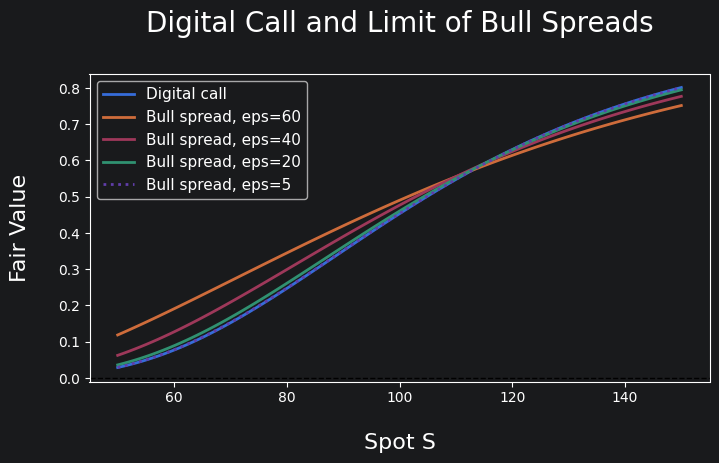

In [47]:
strike = 100
expiry = 1.0
underlying = Stock.BLUECHIP_BANK
spots = np.linspace(50, 150, 100) #will be x axis
# eps_list = [20, 10, 5, 1]
eps_list = [60,40,20,5]

y_digital = [digital_call_value(s, strike, expiry, underlying) for s in spots] #y axis

y_spreads = []
for eps in eps_list:
    y_spreads.append([bull_spread_value(s, strike, eps, expiry, underlying) for s in spots])
my_plotter(
    x=list(spots),
    y=[y_digital] + y_spreads,
    names=['Digital call'] + [f'Bull spread, eps={e}' for e in eps_list],
    layout={'title': 'Digital Call and Limit of Bull Spreads', 'x_label': 'Spot S', 'y_label': 'Fair Value', 'linewidth': 2,
               'legend_fontsize': 11, 'legend_loc': 'upper left'},
    linestyles=['solid']*(len(eps_list)) + ['dotted'],
)

a digital call pays 1 if the stock ends above the strike and zero if it ends below the strike. So the payoff is a graph with a sudden jump at S = K

In the bull spread case we have two calls with the same expiry date.
- we buy a call with a lower strike (K - epsilon)
- we sell a call with a higher strike (K +epsilon)

So at expiry the payoff is
- max(S - (K-epsilon),0) (long one)
- max(S-(K+epsilon),0) (short one)*-1

When we add these two graphs we get a ramp ___/---
if we devide by 2epsilon and we let epsilon aproach zero we converge to the digital call case.
